In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

In [2]:
total_customers = 0
total_revenue = 0.0

def run_experiment(price, n):
    """Returns (mean revenue/customer, standard error). Tracks customers and revenue."""
    global total_customers, total_revenue
    buys = sales(price, mean_customers=n, rng=rng)
    rev = buys * price
    total_customers += len(rev)
    total_revenue += rev.sum()
    if len(rev) < 2:
        return 0.0, float("inf")
    return rev.mean(), rev.std(ddof=1) / np.sqrt(len(rev))


In [3]:
def estimate_slope(price, h = 1, n = 200):
    low_price = max(0,price - h)
    high_price = min(70, price + h)
    r_low = run_experiment(low_price, n)[0]
    r_high = run_experiment(high_price, n)[0]
    return (r_high - r_low) / (high_price - low_price)

def gradient_ascent(start, iterations = 30, h = 1, n = 200, lr = 2):
    price = float(start)
    history = [price]
    for t in range(iterations):
        slope = estimate_slope(price, h, n)
        step = lr / np.sqrt(t+1) * slope
        step = np.clip(step, -2, 2)
        price = float(np.clip(price + step, 0, 70))
        history.append(price)
    return history



start  10: final price 12.19, customers used 11770
start  25: final price 27.53, customers used 11973
start  35: final price 27.62, customers used 11980
start  45: final price 50.27, customers used 11941
start  50: final price 52.66, customers used 11970
start  60: final price 52.48, customers used 12029
start  65: final price 56.85, customers used 11817


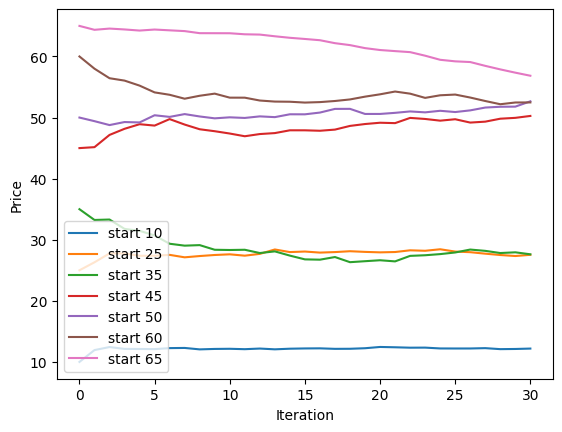

In [4]:
paths = {}
for start in [10, 25, 35, 45, 50, 60, 65]:
    before = total_customers
    paths[start] = gradient_ascent(start)
    print(f"start {start:>3}: final price {paths[start][-1]:.2f}, "
          f"customers used {total_customers - before}")

for start, path in paths.items():
    plt.plot(path, label=f"start {start}")
plt.xlabel("Iteration"); plt.ylabel("Price"); plt.legend(); plt.show()

In [5]:
finals = [paths[s][-1] for s in paths]
for p in finals:
    r = run_experiment(p, 2000)
    print(f"price {p} est revenue/cust {r}")
print(total_customers)

price 12.185567729148444 est revenue/cust (np.float64(11.443942379972162), np.float64(0.06481931384454219))
price 27.53204523428858 est revenue/cust (np.float64(11.942801962512243), np.float64(0.3092307379222479))
price 27.616109806023577 est revenue/cust (np.float64(11.66411827054216), np.float64(0.3048606533193961))
price 50.26545093686557 est revenue/cust (np.float64(7.989535351252158), np.float64(0.4059105524907208))
price 52.65749392773585 est revenue/cust (np.float64(8.407050475031319), np.float64(0.4343373585114279))
price 52.47800289152981 est revenue/cust (np.float64(7.55768398640693), np.float64(0.4150232887620714))
price 56.84580943902928 est revenue/cust (np.float64(6.3328752859742234), np.float64(0.41108010506943965))
97342


In [6]:
def run_experiment_full(price, n):
    global total_customers
    buys = sales(price, mean_customers=n, rng = rng)
    total_customers += len(buys)
    rev = buys * price
    return rev.mean(), rev.std(ddof = 1) / np.sqrt(len(rev))


In [11]:
m_A, se_A = run_experiment_full(12.19, 5000)
m_B, se_B = run_experiment_full(27.53, 5000)

diff = m_B - m_A
se_diff = np.sqrt(se_A**2 + se_B**2)
print(f"A (12.19): {m_A} +- {se_A}")
print(f"B (27.53): {m_B} +- {se_B}")
print(f"B - A = {diff}, 90% CI: ({diff - 1.645*se_diff}, {diff + 1.645*se_diff})")
print("Total customers:", total_customers)

A (12.19): 11.416572226656024 +- 0.04197740085444972
B (27.53): 12.080510904684976 +- 0.1941570875582817
B - A = 0.663938678028952, 90% CI: (0.33717079652396703, 0.990706559533937)
Total customers: 21946


In [8]:
total_customers, total_revenue = 0, 0.0
starts = [10, 27, 40, 55]
finalists = [gradient_ascent(s, iterations=10, n=100)[-1] for s in starts]

finalists

[12.289306814473676, 24.535394508525705, 40.277717826793086, 51.26000932778642]

In [9]:
def get_rev(price, n):
    global total_customers, total_revenue
    rev = sales(price, mean_customers=n, rng=rng) * price
    total_customers += len(rev)
    total_revenue += rev.sum()
    return rev

def summarize(rev):
    return rev.mean(), rev.std(ddof=1) / np.sqrt(len(rev))

def pick_winner(prices, n=1000, max_rounds=4):
    data = {p: get_rev(p, n) for p in prices}
    for _ in range(max_rounds):
        ranked = sorted(data, key=lambda p: -data[p].mean())
        a, b = ranked[0], ranked[1]
        (ma, sa), (mb, sb) = summarize(data[a]), summarize(data[b])
        diff, se = ma - mb, np.sqrt(sa**2 + sb**2)
        print(f"{a:.2f} vs {b:.2f}: diff {diff:.3f}, 90% CI ({diff-1.645*se:.3f}, {diff+1.645*se:.3f})")
        if diff - 1.645 * se > 0:
            break                              
        data[a] = np.concatenate([data[a], get_rev(a, n)])
        data[b] = np.concatenate([data[b], get_rev(b, n)])
    return max(data, key=lambda p: data[p].mean())

In [10]:
rng = np.random.default_rng(100)
total_customers, total_revenue = 0, 0.0

total_customers, total_revenue = 0, 0.0
starts = [10, 27, 40, 55]
finalists = [gradient_ascent(s, iterations=10, n=100)[-1] for s in starts]
winner = pick_winner(finalists)

print("Winner:", winner)
print("Customers used:", total_customers)
print("Revenue per customer during experiments:", total_revenue / total_customers)
print("Share of optimal:", total_revenue / total_customers / 11.925)

27.63 vs 12.37: diff 0.895, 90% CI (0.154, 1.637)
Winner: 27.634891018603636
Customers used: 11982
Revenue per customer during experiments: 9.173097367810263
Share of optimal: 0.7692324836738165
